In [2]:
import os
import glob
import pandas as pd
import numpy as np
import re
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
Spatial_input='2022/Spatial'

In [3]:
def long_routes(folder):
    for filename in os.listdir(folder):
        if filename.endswith(".csv"):  # Chỉ xử lý file CSV
            file_path = os.path.join(folder, filename)
            # Đọc dữ liệu từ file CSV
            df = pd.read_csv(file_path)
            # Lọc các dòng chứa "on to" hoặc "off to" trong MLink_FromIntersection hoặc MLink_ToIntersection
            df_filtered = df[
                df['MLink_FromIntersection'].str.contains("on to", case=False, na=False) |
                df['MLink_FromIntersection'].str.contains("off to", case=False, na=False) |
                df['MLink_ToIntersection'].str.contains("on to", case=False, na=False) |
                df['MLink_ToIntersection'].str.contains("off to", case=False, na=False)
            ]        
            # Lưu kết quả vào file CSV
            df_filtered.to_csv(f'long_routes.csv {filename}', index=False)
            # Hiển thị 10 dòng đầu tiên để kiểm tra
            print(df_filtered[['MLink_FromIntersection', 'MLink_ToIntersection']].head(10))


In [4]:
long_routes(Spatial_input)

                                 MLink_FromIntersection  \
1202  Horrie Miller Dr And Horrie Miller Dr on to To...   
1203  Tonkin Hwy And Tonkin Hwy (Westbound) off to K...   
1204  Tonkin Hwy And Tonkin Hwy (Eastbound) off to R...   
1205  Abernethy Rd And Abernethy Rd on to Tonkin Hwy...   
1206  Tonkin Hwy (Eastbound) off to Roe Hwy (Southbo...   
1207  Roe Hwy And Roe Hwy (Southbound) off to Tonkin...   
1208  Tonkin Hwy (Eastbound) off to Roe Hwy (Southbo...   
1210  Reid Hwy And Reid Hwy (Westbound) on to Mitche...   
1211  Graham Farmer Fwy (Westbound) off to Loftus St...   
1212  Roe Hwy And Roe Hwy (Northbound) off to Berksh...   

                                   MLink_ToIntersection  
1202  Tonkin Hwy And Horrie Miller Dr on to Tonkin H...  
1203  Kewdale Rd And Tonkin Hwy (Westbound) off to K...  
1204  Roe Hwy And Tonkin Hwy (Eastbound) off to Roe ...  
1205  Tonkin Hwy (Eastbound) off to Roe Hwy (Southbo...  
1206  Roe Hwy And Tonkin Hwy (Eastbound) Off Ramp on...  
12

In [5]:
def clean_intersection(intersection):
    """ Xử lý và rút gọn thông tin từ MLink_FromIntersection và MLink_ToIntersection """    
    # Viết tắt hướng đường
    direction_mapping = {
        "Eastbound": "E",
        "Westbound": "W",
        "Northbound": "N",
        "Southbound": "S"
    }

    # Thay thế hướng đường bằng ký hiệu viết tắt
    for full, short in direction_mapping.items():
        intersection = re.sub(rf"\b{full}\b", short, intersection)
    # Bỏ từ "And" nếu không cần thiết
    parts = intersection.split(" And ")
    
    # Nếu hai phần đầu giống nhau thì bỏ phần trùng lặp
    if len(parts) > 1 and parts[0].strip() in parts[1].strip():
        intersection = parts[1]
    
    return intersection.strip()


In [6]:
def apply_intersection(folder):  
    for filename in os.listdir(folder):
        if filename.endswith(".csv"):  # Chỉ xử lý file CSV
            file_path = os.path.join(folder, filename)
            # Đọc dữ liệu từ file CSV
            df = pd.read_csv(file_path)
            # Áp dụng hàm xử lý cho MLink_FromIntersection và MLink_ToIntersection
            df["MLink_FromIntersection_Cleaned"] = df["MLink_FromIntersection"].apply(clean_intersection)
            df["MLink_ToIntersection_Cleaned"] = df["MLink_ToIntersection"].apply(clean_intersection)
            #Kết hợp thành MLink_Route
            df["MLink_Route"] = df["MLink_FromIntersection_Cleaned"] + "/" + df["MLink_ToIntersection_Cleaned"]
            df = df.drop(columns=["MLink_FromIntersection_Cleaned","MLink_ToIntersection_Cleaned"])
            # Lưu file kết quả
            df.to_csv(file_path, index=False)

In [7]:
apply_intersection(Spatial_input)

In [8]:
def extract_first_point(polyline):
    """Trích xuất tọa độ đầu tiên (lat, lon) từ chuỗi LINESTRING hoặc MULTILINESTRING."""
    match = re.search(r"[-+]?\d*\.\d+ [-+]?\d*\.\d+", polyline)
    if match:
        lon, lat = match.group().split()  # Tách thành kinh độ (Longitude) và vĩ độ (Latitude)
        return float(lat), float(lon)  # Đưa về dạng số thực
    return None, None  # Trường hợp không tìm thấy

def process_csv_files(folder):
    """Duyệt qua tất cả các file CSV trong thư mục và xử lý."""
    for filename in os.listdir(folder):
        if filename.endswith(".csv"):  # Chỉ xử lý file CSV
            file_path = os.path.join(folder, filename)
            print(f"Processing{file_path}")

            # Đọc dữ liệu từ CSV
            df = pd.read_csv(file_path)

            # Kiểm tra nếu cột 'IRIS_Polyline' tồn tại
            if 'IRIS_Polyline' in df.columns:
                # Áp dụng hàm để tạo cột Latitude và Longitude
                df[['Latitude', 'Longitude']] = df['IRIS_Polyline'].apply(lambda x: pd.Series(extract_first_point(str(x))))
                
                # Lưu lại file sau khi xử lý
                # output_path = os.path.join(folder, "processed_" + filename)
                df.to_csv(file_path, index=False)
                print(f"Saved: {file_path}")


In [9]:
# Chạy chương trình
process_csv_files(Spatial_input)

Processing2022/Spatial\2022-11.csv
Saved: 2022/Spatial\2022-11.csv
Processing2022/Spatial\2022-12.csv
Saved: 2022/Spatial\2022-12.csv


In [5]:
Data_input ='2022/Data'

In [11]:
def split_and_format_datetime(folder):
    # Duyệt qua tất cả các file CSV trong thư mục
    for filename in os.listdir(folder):
        if filename.endswith(".csv"):  # Chỉ xử lý file CSV
            file_path = os.path.join(folder, filename)
            
            # Đọc file CSV
            df = pd.read_csv(file_path)
            
            # Kiểm tra xem cột 'Date Time AWST' có tồn tại không
            if 'Date Time AWST' in df.columns:
                # Tách thành cột Date và Time
                df[['Date', 'Time']] = df['Date Time AWST'].str.split('T', expand=True)

                # Định dạng Date và Time
                df['Date'] = pd.to_datetime(df['Date']).dt.strftime('%Y-%m-%d')  # Format YYYY-MM-DD
                df['Time'] = pd.to_datetime(df['Time'], format='%H:%M').dt.strftime('%H:%M')  # Format HH:MM

                # Tạo cột DateTime với format chuẩn
                # df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])

                # Xóa cột cũ
                df.drop(columns=['Date Time AWST'], inplace=True)

                # Ghi đè file CSV đã xử lý
                # output_path = os.path.join(folder, "processed_" + filename)
                df.to_csv(file_path, index=False)
                print(f"Processed: {file_path}")
            else:
                print(f"Skipping {filename} - No 'Date Time AWST' column found")

In [12]:
split_and_format_datetime(Data_input)

Processed: 2022/Data\2022-11.csv
Processed: 2022/Data\2022-12.csv


In [13]:
def drop_col(folder):
    for filename in os.listdir(folder):
        if filename.endswith('.csv'):
            file_path = os.path.join(folder, filename)
            df = pd.read_csv(file_path)

            # Chỉ xóa cột nếu nó tồn tại trong DataFrame
            cols_to_drop = ['TravelTimeMinutes', 'TTQuality']
            existing_cols = [col for col in cols_to_drop if col in df.columns]

            if existing_cols:
                df = df.drop(columns=existing_cols)
                df.to_csv(file_path, index=False)
                print(f"Processed: {file_path}")
            else:
                print(f"Skipped (columns not found): {file_path}")

drop_col(Data_input)

Processed: 2022/Data\2022-11.csv
Processed: 2022/Data\2022-12.csv


In [14]:
def data_checking(folder):
    # Duyệt qua tất cả các file CSV trong thư mục
    for filename in os.listdir(folder):
        if filename.endswith(".csv"):  # Chỉ xử lý file CSV
            file_path = os.path.join(folder, filename)
            
            # Đọc file CSV
            df = pd.read_csv(file_path)
            print(f'This is the info for {filename}')
            print(df.isna().sum())
            print(df['MLinkID'].nunique())

data_checking(Data_input)

This is the info for 2022-11.csv
MLinkID          0
AverageLanes     0
Volume           0
VolumeQuality    0
Date             0
Time             0
dtype: int64
3839
This is the info for 2022-12.csv
MLinkID          0
AverageLanes     0
Volume           0
VolumeQuality    0
Date             0
Time             0
dtype: int64
3843


In [25]:
def check_removeduplicate(folder):
    for filename in os.listdir(folder):
        if filename.endswith(".csv"):  # Chỉ xử lý file CSV
            file_path = os.path.join(folder, filename)
            
            # Đọc file CSV
            df = pd.read_csv(file_path)

            # Loại bỏ các dòng trùng lặp
            df = df.drop_duplicates(subset=["MLinkID"])
            print(df.duplicated(subset=["MLinkID"]).sum())

            # Ghi đè file CSV sau khi xử lý
            df.to_csv(file_path, index=False)
            print(f"Already handled: {filename} - The length remain: {len(df)}")

# Gọi hàm với đường dẫn thư mục chứa các file CSV
check_removeduplicate(Spatial_input)


0
Already handled: 2022-11.csv - The length remain: 4828
0
Already handled: 2022-12.csv - The length remain: 4826


In [26]:
def merge_data(data_folder, spatial_folder):
    # Create an output folder if it does not exist
    output_folder = "Merged_Data"
    os.makedirs(output_folder, exist_ok=True)

    # List all CSV files in both folders
    data_files = {f for f in os.listdir(data_folder) if f.endswith(".csv")}
    spatial_files = {f for f in os.listdir(spatial_folder) if f.endswith(".csv")}

    # Identify files with the same name in both folders
    common_files = data_files & spatial_files  # Only select common files

    # Check if there are no matching files
    if not common_files:
        print("No matching files found between the two folders.")
        return

    # Iterate over each common file
    for file_name in sorted(common_files):  # Sort to ensure order
        print(f"Processing: {file_name}")  # Display progress
        
        # Read the file from the data folder
        data_df = pd.read_csv(os.path.join(data_folder, file_name))

        # Read the file from the spatial folder, selecting only necessary columns
        spatial_df = pd.read_csv(os.path.join(spatial_folder, file_name), usecols=["MLinkID", "Latitude", "Longitude", "MLink_Route"])

        # Merge based on MLinkID, keeping only the MLinkID values present in data_df
        merged_df = data_df.merge(spatial_df, on="MLinkID", how="left")

        # Save the merged file
        output_path = os.path.join(output_folder, file_name)
        merged_df.to_csv(output_path, index=False)
        print(f"✔️ Merge completed: {output_path}")

    print("Merge process completed! Files saved in the 'Merged_Data' folder.")


In [27]:
merge_data(Data_input,Spatial_input)

Processing: 2022-11.csv
✔️ Merge completed: Merged_Data\2022-11.csv
Processing: 2022-12.csv
✔️ Merge completed: Merged_Data\2022-12.csv
Merge process completed! Files saved in the 'Merged_Data' folder.


In [28]:
merged_input = 'Merged_Data'

In [35]:
def separatedMLink():
    input_dir = 'Merged_data'  # Thư mục chứa các file CSV gốc
    output_dir = 'Seperated_MLink'  # Thư mục lưu kết quả
    os.makedirs(output_dir, exist_ok=True)

    # Danh sách tất cả file CSV trong thư mục Merged_data
    csv_files = [f for f in os.listdir(input_dir) if f.endswith('.csv')]

    # Gộp tất cả dữ liệu từ các file CSV
    all_data = pd.DataFrame()  # DataFrame rỗng để chứa dữ liệu gộp
    
    for file in csv_files:
        file_path = os.path.join(input_dir, file)
        df = pd.read_csv(file_path)
        
        # Kiểm tra nếu cột 'MLinkID' hoặc 'MLink_Route' không tồn tại
        if 'MLinkID' not in df.columns or 'MLink_Route' not in df.columns:
            print(f"Skipping {file}: Missing required columns.")
            continue
        
        all_data = pd.concat([all_data, df], ignore_index=True)  # Nối dữ liệu từ file hiện tại vào all_data
    
    # Kiểm tra nếu không có dữ liệu hợp lệ
    if all_data.empty:
        print("No valid data found. Exiting.")
        return

    # Nhóm theo 'MLinkID' và 'MLink_Route'
    grouped = all_data.groupby(['MLinkID', 'MLink_Route'])

    for (mlink_id, mlink_route), group in grouped:
        # Xử lý tên file an toàn
        safe_mlink_route = re.sub(r'[^a-zA-Z0-9_ -]', '', str(mlink_route))
        safe_mlink_route = " ".join(safe_mlink_route.split())  # Chuẩn hóa khoảng trắng
        
        file_name = f"{mlink_id}_{safe_mlink_route}.csv"
        output_file_path = os.path.join(output_dir, file_name)
        
        # Loại bỏ dòng trùng lặp trước khi lưu
        group = group.drop_duplicates()
        group.to_csv(output_file_path, index=False)
        print(f"Saved: {output_file_path}")

# Gọi hàm để thực thi
separatedMLink()


Saved: Seperated_MLink\71_Point Lewis RtyMitchell Fwy S Off.csv
Saved: Seperated_MLink\72_Mitchell Fwy S OffMitchell Fwy S.csv
Saved: Seperated_MLink\73_Mitchell Fwy SWilliam St.csv
Saved: Seperated_MLink\74_William StMitchell Fwy S.csv
Saved: Seperated_MLink\75_Mitchell Fwy SPoint Lewis Rty.csv
Saved: Seperated_MLink\76_Point Lewis RtyHackett Dr.csv
Saved: Seperated_MLink\77_Hackett DrWinthrop Av.csv
Saved: Seperated_MLink\78_Winthrop AvBroadway Hampden Rd.csv
Saved: Seperated_MLink\79_Broadway Hampden RdDalkeith Rd.csv
Saved: Seperated_MLink\80_Dalkeith RdLoch St.csv
Saved: Seperated_MLink\81_Loch StLeura Av.csv
Saved: Seperated_MLink\82_Leura AvBay View Tce.csv
Saved: Seperated_MLink\83_Bay View TceStirling Rd Queenslea Dr.csv
Saved: Seperated_MLink\84_Stirling Rd Queenslea DrEric St Osborne Pde.csv
Saved: Seperated_MLink\85_Eric St Osborne PdeLeake St Napoleon St.csv
Saved: Seperated_MLink\86_Leake St Napoleon StJarrad St.csv
Saved: Seperated_MLink\87_Jarrad StGlyde St.csv
Saved: S

In [ ]:
def count_files_in_folder(folder_path):
    """ 
        Count the total number of files in a folder.  
            :param folder_path: Path to the folder to count files  
            :return: Total number of files in the folder
    """
    if not os.path.isdir(folder_path):
        print("Invalid path or not a directory.")
        return 0
    
    return len([f for f in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, f))])

count_files_in_folder('Seperated_MLink')

3851

In [ ]:
def count_MLink_merged(folder='Merged_Data'):
    unique_mlinks = set()  # Sử dụng tập hợp để lưu giá trị duy nhất

    for filename in os.listdir(folder):
        if filename.endswith('.csv'):
            file_path = os.path.join(folder, filename)
            df = pd.read_csv(file_path)
            unique_mlinks.update(df['MLinkID'].unique())  # Thêm các giá trị mới vào tập hợp
    
    print(f'Total number of unique MLinkIDs across all files: {len(unique_mlinks)}')

count_MLink_merged()

Tổng số MLinkID duy nhất trong tất cả các file: 3851


In [5]:
# Thư mục chứa các file CSV
folder_path = "Seperated_MLink"

# Số dòng kỳ vọng (15 phút x 24 giờ x 30 ngày x 2 tháng)
expected_rows = 5856

# Lưu kết quả
file_counts = []

# Duyệt qua từng file trong thư mục
for file in os.listdir(folder_path):
    if file.endswith(".csv"):
        file_path = os.path.join(folder_path, file)
        
        # Đọc dữ liệu
        df = pd.read_csv(file_path)

        # Kiểm tra xem có đủ cột 'Date' và 'Time' không
        if "Date" not in df.columns or "Time" not in df.columns:
            print(f" File {file} does not contain Date or Time columns!")
            continue
        
        # Tạo cột datetime bằng cách kết hợp 'Date' và 'Time'
        df["Datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"], errors="coerce")

        # Lọc dữ liệu theo tháng 11 và 12 năm 2022
        df_filtered = df[(df["Datetime"].dt.year == 2022) & (df["Datetime"].dt.month.isin([11, 12]))]

        # Đếm số dòng sau khi lọc
        row_count = len(df_filtered)
        
        missing_percentage = (1 - row_count / expected_rows) * 100


        # Ghi lại kết quả
        file_counts.append({
            "File": file,
            "Row Count": row_count,
            "Missing Data (%)":  missing_percentage
        })

# Chuyển kết quả thành DataFrame
df_counts = pd.DataFrame(file_counts)

#Chỉ lọc những file có dữ liệu thiếu trên 20%
severely_missing_files = df_counts[df_counts["Missing Data (%)"] > 20]

# In kết quả
print(f"Total files missing more than 20% of data: {len(severely_missing_files)}")
print("Files with More than 20% Missing Data:")
print(severely_missing_files)

Total files missing more than 20% of data: 0
Files with More than 20% Missing Data:
Empty DataFrame
Columns: [File, Row Count, Missing Data (%)]
Index: []


In [14]:
def delete_severely_missing_files(folder_path, threshold=20):
    """
        Delete CSV files in the folder that have missing data above a specified threshold.

        Parameters:
            - folder_path (str): Path to the folder containing CSV files.
            - threshold (float): Percentage threshold of missing data to delete the file (default is 20%).
    """

    expected_rows = 5856  # Số dòng kỳ vọng (15 phút x 24 giờ x 30 ngày x 2 tháng)
    file_counts = []
    
    for file in os.listdir(folder_path):
        if file.endswith(".csv"):
            file_path = os.path.join(folder_path, file)
            
            df = pd.read_csv(file_path)
            
            if "Date" not in df.columns or "Time" not in df.columns:
                print(f"Skipping {file} - Missing Date or Time column.")
                continue
            
            df["Datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"], errors="coerce")
            df_filtered = df[(df["Datetime"].dt.year == 2022) & (df["Datetime"].dt.month.isin([11, 12]))]
            
            row_count = len(df_filtered)
            missing_percentage = (1 - row_count / expected_rows) * 100
            
            if missing_percentage > threshold:
                os.remove(file_path)
                print(f"Deleted: {file} ({missing_percentage:.2f}% missing data)")

# Gọi hàm để xóa file thiếu trên 20%
folder_path = "Seperated_MLink"
delete_severely_missing_files(folder_path, threshold=20)

Deleted: 1072_Great Eastern Hwy WAlbany Hwy.csv (49.18% missing data)
Deleted: 1075_Canning Hwy BusCanning Hwy E to Causeway.csv (49.18% missing data)
Deleted: 1153_Lakes Rd OffLakes Rd On.csv (40.44% missing data)
Deleted: 1155_Pinjarra Rd OffPinjarra Rd On.csv (40.44% missing data)
Deleted: 1160_Lakes Rd OffLakes Rd On.csv (27.48% missing data)
Deleted: 1385_Lagoon Dr Peony BvdGraceful Bvd.csv (84.12% missing data)
Deleted: 142_Sutherland St OnGraham Farmer Fwy.csv (45.94% missing data)
Deleted: 1446_Logger RdMetropolitan Area Boundary.csv (45.03% missing data)
Deleted: 1447_Metropolitan Area BoundaryLogger Rd.csv (44.60% missing data)
Deleted: 1454_Clondyke RdJarrahdale Rd Shanley Rd.csv (21.93% missing data)
Deleted: 1455_Jarrahdale Rd Shanley RdClondyke Rd.csv (24.04% missing data)
Deleted: 1457_Brand Hwy RtyTonkin Hwy NB.csv (83.54% missing data)
Deleted: 1459_Granary Dr OnEnd 290.csv (22.73% missing data)
Deleted: 1460_End 290Granary Dr Off.csv (22.90% missing data)
Deleted: 146

In [ ]:
def count_files_in_folder(folder_path):
    """ 
        Count the total number of files in a folder.  
            :param folder_path: Path to the folder to count files  
            :return: Total number of files in the folder
    """
    if not os.path.isdir(folder_path):
        print("Invalid path or not a directory.")
        return 0
    
    return len([f for f in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, f))])

count_files_in_folder('Seperated_MLink')

3724

In [16]:
# Đường dẫn đến thư mục chứa CSV
folder_path = "Seperated_MLink"

# Danh sách các file CSV trong thư mục
csv_files = [f for f in os.listdir(folder_path) if f.endswith('.csv')]

# Duyệt qua từng file và lưu kết quả thống kê
stats_dict = {}

for file in csv_files:
    file_path = os.path.join(folder_path, file)
    
    # Đọc dữ liệu
    df = pd.read_csv(file_path)
    
    # Kiểm tra nếu Volume tồn tại
    if 'Volume' in df.columns:
        stats_dict[file] = df['Volume'].describe()

# Chuyển kết quả thành DataFrame để hiển thị
stats_df = pd.DataFrame(stats_dict).T  # Chuyển vị để file là index

# Hiển thị kết quả
print(stats_df)

# Nếu muốn lưu vào file CSV
stats_df.to_csv("volume_descriptive_stats.csv")
print( "Descriptive statistics saved to volume_descriptive_stats.csv")

                                                    count        mean  \
1000_Hay StHay St On.csv                           5855.0  159.188215   
1001_Hay St OnGreat Eastern Hwy E Off.csv          5856.0  225.483265   
1002_Great Eastern Hwy E OffCanning Hwy W Off.csv  5856.0  207.934768   
1003_Canning Hwy W OffGreat Eastern Hwy W.csv      5772.0  146.361227   
1004_Great Eastern Hwy WTeddington Rd.csv          5845.0  134.504705   
...                                                   ...         ...   
98_Wellington StVictoria St.csv                    5856.0  159.846311   
990_Hale RdRoe Hwy Off.csv                         5856.0  250.084529   
998_Horrie Miller Dr FederalTonkin Hwy.csv         5853.0   73.643260   
999_Adelaide TceHay St.csv                         5759.0  186.685362   
99_Victoria StGlyde St.csv                         5856.0  128.541837   

                                                          std  min    25%  \
1000_Hay StHay St On.csv                      

In [17]:
def count_outliers_iqr(folder_path, column='Volume'):
    outlier_counts = {}

    # Duyệt qua tất cả các file CSV trong thư mục
    for file in os.listdir(folder_path):
        if file.endswith('.csv'):
            file_path = os.path.join(folder_path, file)
            df = pd.read_csv(file_path)

            if column in df.columns:
                Q1 = df[column].quantile(0.25)
                Q3 = df[column].quantile(0.75)
                IQR = Q3 - Q1

                lower_bound = Q1 - 1.5 * IQR
                upper_bound = Q3 + 1.5 * IQR

                outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
                outlier_counts[file] = len(outliers)

    return outlier_counts

# Đặt đường dẫn đến thư mục chứa các file CSV
folder_path = "Seperated_MLink"  # Thay đổi thành đường dẫn thực tế

# Chạy hàm và in kết quả
outlier_results = count_outliers_iqr(folder_path)
for file, count in outlier_results.items():
    print(f"File: {file} - Outliers: {count}")


File: 1000_Hay StHay St On.csv - Outliers: 245
File: 1001_Hay St OnGreat Eastern Hwy E Off.csv - Outliers: 236
File: 1002_Great Eastern Hwy E OffCanning Hwy W Off.csv - Outliers: 148
File: 1003_Canning Hwy W OffGreat Eastern Hwy W.csv - Outliers: 152
File: 1004_Great Eastern Hwy WTeddington Rd.csv - Outliers: 200
File: 1005_Teddington RdDuncan St.csv - Outliers: 270
File: 1006_Duncan StMiller St.csv - Outliers: 236
File: 1007_Miller StMint St.csv - Outliers: 114
File: 1008_Mint StOats St Hill View Tce.csv - Outliers: 71
File: 1009_Oats St Hill View TceWelshpool Rd Albany Hwy.csv - Outliers: 82
File: 100_Glyde StJarrad St.csv - Outliers: 0
File: 1010_Welshpool Rd Albany HwyAshburton St John St.csv - Outliers: 0
File: 1011_Ashburton Stj John StBedford St Ewing St.csv - Outliers: 0
File: 1012_Bedford St Ewing StLeach Hwy E.csv - Outliers: 0
File: 1013_Leach Hwy ELeach Hwy W.csv - Outliers: 0
File: 1014_Leach Hwy WHamilton St.csv - Outliers: 0
File: 1015_Hamilton StManning Rd Mallard Wy.cs

In [19]:
def handle_outliers_iqr(folder_path, column='Volume', output_folder='Processed_MLink'):
    # Tạo thư mục đầu ra nếu chưa tồn tại
    os.makedirs(output_folder, exist_ok=True)

    for file in os.listdir(folder_path):
        if file.endswith('.csv'):
            file_path = os.path.join(folder_path, file)
            df = pd.read_csv(file_path)

            if column in df.columns:
                Q1 = df[column].quantile(0.25)
                Q3 = df[column].quantile(0.75)
                IQR = Q3 - Q1

                lower_bound = Q1 - 1.5 * IQR
                upper_bound = Q3 + 1.5 * IQR

                # Dữ liệu lớn hơn 3000 dòng → Loại bỏ outliers
                df_filtered = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]
                method = "Removed outliers"

                # Lưu file đã xử lý vào thư mục mới
                output_path = os.path.join(output_folder, file)
                df_filtered.to_csv(output_path, index=False)

                print(f"Processed: {file} - Original: {len(df)}, After Processing: {len(df_filtered)}, Method: {method}")

# Đặt đường dẫn thư mục đầu vào và đầu ra
folder_path = "Seperated_MLink"  # Thay đổi thành đường dẫn thực tế
output_folder = "Processed_MLink"

# Gọi hàm để xử lý và lưu file
handle_outliers_iqr(folder_path, column='Volume', output_folder=output_folder)

Processed: 1000_Hay StHay St On.csv - Original: 5855, After Processing: 5610, Method: Removed outliers
Processed: 1001_Hay St OnGreat Eastern Hwy E Off.csv - Original: 5856, After Processing: 5620, Method: Removed outliers
Processed: 1002_Great Eastern Hwy E OffCanning Hwy W Off.csv - Original: 5856, After Processing: 5708, Method: Removed outliers
Processed: 1003_Canning Hwy W OffGreat Eastern Hwy W.csv - Original: 5772, After Processing: 5620, Method: Removed outliers
Processed: 1004_Great Eastern Hwy WTeddington Rd.csv - Original: 5845, After Processing: 5645, Method: Removed outliers
Processed: 1005_Teddington RdDuncan St.csv - Original: 5845, After Processing: 5575, Method: Removed outliers
Processed: 1006_Duncan StMiller St.csv - Original: 5849, After Processing: 5613, Method: Removed outliers
Processed: 1007_Miller StMint St.csv - Original: 5856, After Processing: 5742, Method: Removed outliers
Processed: 1008_Mint StOats St Hill View Tce.csv - Original: 5856, After Processing: 

In [20]:
# Đường dẫn đến thư mục chứa CSV
folder_path = "Processed_MLink"

# Danh sách các file CSV trong thư mục
csv_files = [f for f in os.listdir(folder_path) if f.endswith('.csv')]

# Duyệt qua từng file và lưu kết quả thống kê
stats_dict = {}

for file in csv_files:
    file_path = os.path.join(folder_path, file)
    
    # Đọc dữ liệu
    df = pd.read_csv(file_path)
    
    # Kiểm tra nếu Volume tồn tại
    if 'Volume' in df.columns:
        stats_dict[file] = df['Volume'].describe()

# Chuyển kết quả thành DataFrame để hiển thị
stats_df = pd.DataFrame(stats_dict).T  # Chuyển vị để file là index

# Hiển thị kết quả
print(stats_df)

# Nếu muốn lưu vào file CSV
stats_df.to_csv("volume_after.csv")
print( "Descriptive statistics after handling outliers saved to volume_after.csv")

                                                    count        mean  \
1000_Hay StHay St On.csv                           5610.0  144.963993   
1001_Hay St OnGreat Eastern Hwy E Off.csv          5620.0  205.891815   
1002_Great Eastern Hwy E OffCanning Hwy W Off.csv  5708.0  196.705501   
1003_Canning Hwy W OffGreat Eastern Hwy W.csv      5620.0  138.374377   
1004_Great Eastern Hwy WTeddington Rd.csv          5645.0  124.652259   
...                                                   ...         ...   
98_Wellington StVictoria St.csv                    5856.0  159.846311   
990_Hale RdRoe Hwy Off.csv                         5856.0  250.084529   
998_Horrie Miller Dr FederalTonkin Hwy.csv         5631.0   66.214349   
999_Adelaide TceHay St.csv                         5579.0  175.020255   
99_Victoria StGlyde St.csv                         5856.0  128.541837   

                                                          std  min    25%  \
1000_Hay StHay St On.csv                      

In [37]:
import os
import pandas as pd

# Bước 1: Duyệt qua folder Processed_MLink để lấy danh sách MLinkID
processed_folder = "Processed_MLink"
mlink_ids = set()

for file in os.listdir(processed_folder):
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(processed_folder, file))
        if 'MLinkID' in df.columns:
            mlink_ids.update(df['MLinkID'].unique())

# Bước 2: Đọc file 2022-11.csv và 2022-12.csv trong folder 2022/Spatial
spatial_folder = "2022/Spatial"
spatial_files = ["2022-11.csv", "2022-12.csv"]
spatial_data = pd.DataFrame()

for file in spatial_files:
    file_path = os.path.join(spatial_folder, file)
    if os.path.exists(file_path):
        df_spatial = pd.read_csv(file_path)
        if {'MLinkID', 'MLink_Type'}.issubset(df_spatial.columns):
            spatial_data = pd.concat([spatial_data, df_spatial[['MLinkID', 'MLink_Type']]])

# Bước 3: Lọc dữ liệu theo MLinkID đã tìm được
spatial_data = spatial_data[spatial_data['MLinkID'].isin(mlink_ids)]

# Loại bỏ giá trị trùng lặp nếu có
spatial_data = spatial_data.drop_duplicates()

# Xuất dữ liệu hoặc xem trước
print(spatial_data.head())

# Lưu kết quả nếu cần
spatial_data.to_csv("MLinkID_with_Type.csv", index=False)


   MLinkID MLink_Type
0       71        Art
1       72        Art
2       73        Art
3       74        Art
4       75        Art


In [ ]:
import pandas as pd
import os

# Bước 1: Đọc file MLinkID_with_Type.csv và lọc MLinkID có MLink_Type = Local
mlink_type_df = pd.read_csv("MLinkID_with_Type.csv")
local_mlinks = set(mlink_type_df[mlink_type_df["MLink_Type"] == "Local"]["MLinkID"].astype(str))

# Bước 2: Lấy danh sách file trong thư mục Processed_MLink
processed_folder = "Processed_MLink"
matching_files = []

for filename in os.listdir(processed_folder):
    if "_" in filename and filename.endswith(".csv"):
        mlink_id = filename.split("_")[0]  # Lấy giá trị trước dấu _
        if mlink_id in local_mlinks:
            matching_files.append(os.path.join(processed_folder, filename))

# Bước 3: Đọc file phù hợp và tính phần trăm giá trị Volume > 500
for file in matching_files:
    df = pd.read_csv(file)
    if "Volume" in df.columns:
        percentage = (df["Volume"] > 500).mean() * 100
        if percentage > 20:  # Chỉ in nếu % > 50%
            print(f"File: {file}, Phần trăm Volume > 500: {percentage:.2f}%")


File: Processed_MLink\55443_Graham Farmer Fwy W off to Loftus St Cambridge StLoftus St.csv, Phần trăm Volume > 500: 25.68%
File: Processed_MLink\57139_Ley StLockhart St Canning Hwy to Manning Rd Manning Rd on to Kwinana Fwy N.csv, Phần trăm Volume > 500: 23.83%
File: Processed_MLink\58330_Loftus StLeederville Pde Loftus St on to Graham Farmer Fwy E.csv, Phần trăm Volume > 500: 25.75%
File: Processed_MLink\65494_Graham Farmer Fwy W off to Loftus St Cambridge StLoftus St.csv, Phần trăm Volume > 500: 49.74%


Files to process: ['55443_Graham Farmer Fwy W off to Loftus St Cambridge StLoftus St.csv', '57139_Ley StLockhart St Canning Hwy to Manning Rd Manning Rd on to Kwinana Fwy N.csv', '58330_Loftus StLeederville Pde Loftus St on to Graham Farmer Fwy E.csv', '65494_Graham Farmer Fwy W off to Loftus St Cambridge StLoftus St.csv']


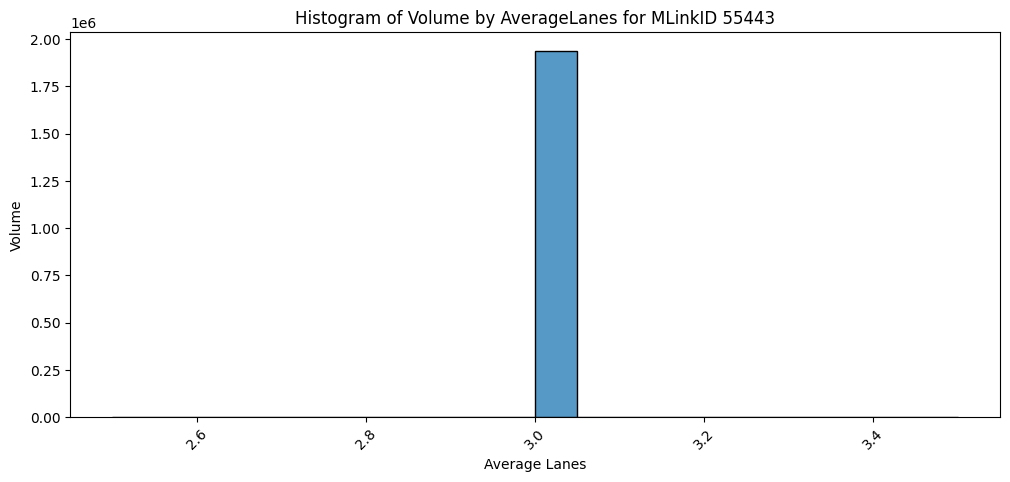

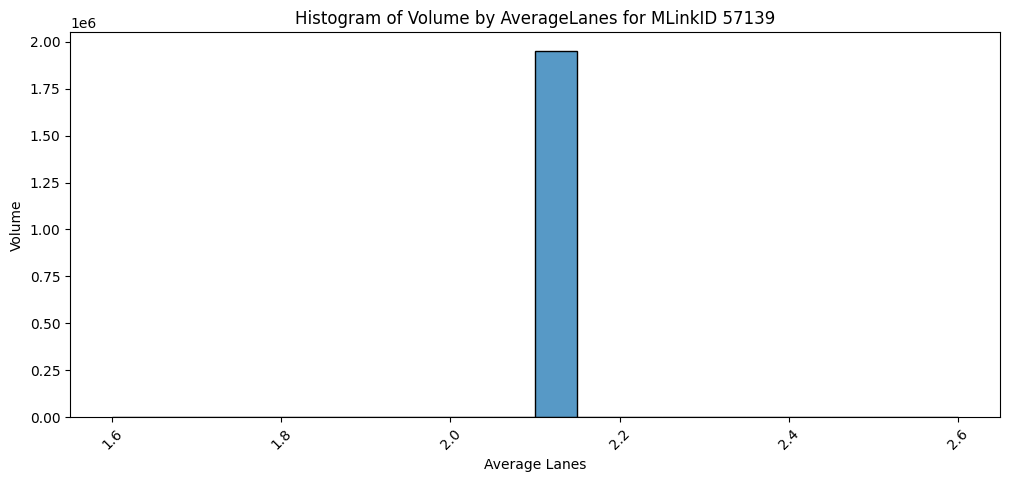

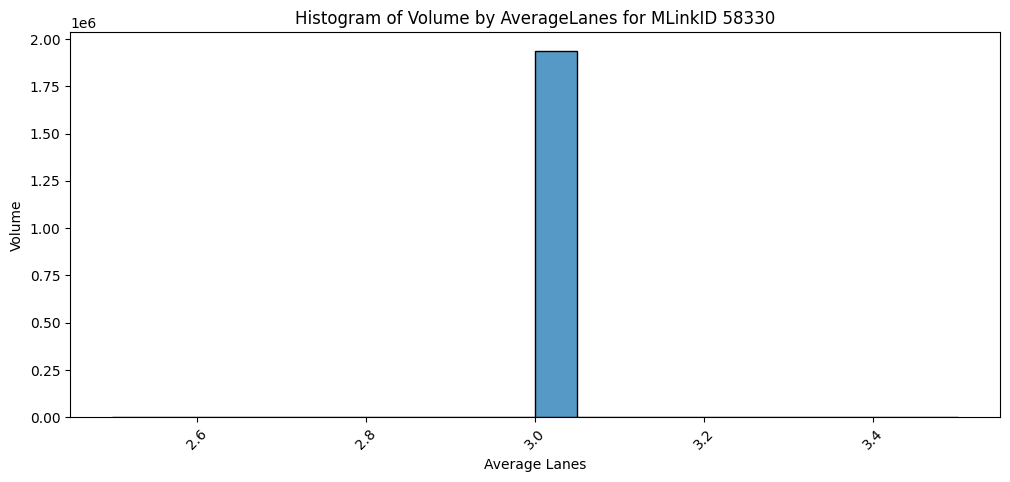

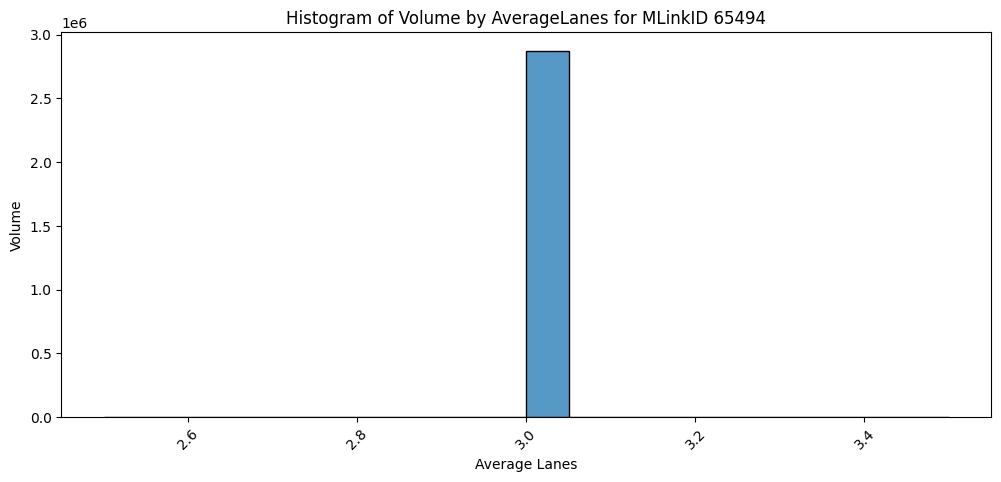

In [51]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thư mục chứa file CSV
folder_path = "Processed_MLink"

# Danh sách MLinkID cần lọc
mlinks_target = {55443, 57139, 58330, 65494}

# Lấy danh sách file CSV trong thư mục
csv_files = [f for f in os.listdir(folder_path) if f.endswith('.csv')]

# Lọc file theo MLinkID
filtered_files = []
for file in csv_files:
    mlink_id = file.split("_")[0]  # Tách phần trước dấu '_'
    if mlink_id.isdigit() and int(mlink_id) in mlinks_target:
        filtered_files.append(file)

# Kiểm tra danh sách file đã lọc
print("Files to process:", filtered_files)

# Vẽ histplot cho Volume theo Time của từng file
for file in filtered_files:
    mlink_id = file.split("_")[0]
    file_path = os.path.join(folder_path, file)
    
    # Đọc file CSV
    df = pd.read_csv(file_path)
    
    # Kiểm tra nếu cột "AverageLanes" có giá trị hợp lệ
    if "AverageLanes" in df.columns and "Volume" in df.columns:
        plt.figure(figsize=(12, 5))
        sns.histplot(data=df, x="AverageLanes", weights="Volume", bins=20, kde=False)
        plt.xticks(rotation=45)
        plt.title(f"Histogram of Volume by AverageLanes for MLinkID {mlink_id}")
        plt.xlabel("Average Lanes")
        plt.ylabel("Volume")
        plt.show()
    else:
        print(f"⚠️ Warning: File {file} does not contain required columns!")


In [39]:
def split_all_csv(input_dir='Processed_MLink', output_dir='Splitted_MLink', split_ratio=0.8):
    """
        Splits all CSV files in the 'SeperatedMLink' directory into train/test sets, 
        then saves the results in the 'Splitted_MLink' directory.

        - input_dir: Directory containing the original CSV files.
        - output_dir: Directory to save the train/test files.
        - split_ratio: Training data ratio (default is 80% train, 20% test).
    """

    # Tạo thư mục đầu ra nếu chưa có
    os.makedirs(output_dir, exist_ok=True)

    # Lấy danh sách tất cả các file CSV trong input_dir
    csv_files = glob.glob(os.path.join(input_dir, "*.csv"))

    for file_path in csv_files:
        # Lấy tên file gốc (không có phần mở rộng .csv)
        file_name = os.path.basename(file_path).replace('.csv', '')

        # Đọc dữ liệu từ file CSV
        df = pd.read_csv(file_path)

        # Xác định index để chia tập dữ liệu
        split_index = int(len(df) * split_ratio)

        # Chia dữ liệu thành train và test
        train_df = df.iloc[:split_index]
        test_df = df.iloc[split_index:]

        # Lưu file train và test
        train_file = os.path.join(output_dir, f"{file_name}_train.csv")
        test_file = os.path.join(output_dir, f"{file_name}_test.csv")

        train_df.to_csv(train_file, index=False)
        test_df.to_csv(test_file, index=False)

        print(f"Splitted successful and saved : {file_name}-{len(train_df)}-{len(test_df)}")
split_all_csv()

Splitted successful and saved : 1000_Hay StHay St On-4488-1122
Splitted successful and saved : 1001_Hay St OnGreat Eastern Hwy E Off-4496-1124
Splitted successful and saved : 1002_Great Eastern Hwy E OffCanning Hwy W Off-4566-1142
Splitted successful and saved : 1003_Canning Hwy W OffGreat Eastern Hwy W-4496-1124
Splitted successful and saved : 1004_Great Eastern Hwy WTeddington Rd-4516-1129
Splitted successful and saved : 1005_Teddington RdDuncan St-4460-1115
Splitted successful and saved : 1006_Duncan StMiller St-4490-1123
Splitted successful and saved : 1007_Miller StMint St-4593-1149
Splitted successful and saved : 1008_Mint StOats St Hill View Tce-4628-1157
Splitted successful and saved : 1009_Oats St Hill View TceWelshpool Rd Albany Hwy-4619-1155
Splitted successful and saved : 100_Glyde StJarrad St-4684-1172
Splitted successful and saved : 1010_Welshpool Rd Albany HwyAshburton St John St-4684-1172
Splitted successful and saved : 1011_Ashburton Stj John StBedford St Ewing St-4684